# Modeling Human Activity States with a Hidden Markov Model

This notebook is my individual work for Formative 2. I recorded accelerometer and gyroscope data with Sensor Logger on my iPhone 13, turned it into features, and built a Hidden Markov Model from scratch with numpy. The model uses Baum-Welch for training and Viterbi for decoding.

Use case: I am building a platform that makes home construction in Rwanda more transparent. Knowing when a worker is standing, walking, jumping down from something, or leaving a phone or tool still could help track real activity on a building site. A phone in a pocket or on a belt is cheap, and a model that reads its motion can tell the difference between active work and idle time.

Folder layout this notebook expects:

* `raw_zips/` holds all the Sensor Logger zip files, named like `jumping-01-...zip`, `stand-01-...zip`, `walking-01-...zip`, `still-01-...zip`, `test-01-...zip`
* `data/` is created by the notebook and holds the cleaned, labeled CSV files
* `figures/` and `results/` are also created by the notebook

## 1. Settings

In [1]:
import os, re, io, glob, zipfile, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
RAW_DIR = "raw_zips"
DATA_DIR = "data"
FIG_DIR = "figures"
RES_DIR = "results"
for d in (DATA_DIR, FIG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

FS = 100              # common sampling rate in Hz for every recording
WINDOW_SEC = 2.0      # window length in seconds
OVERLAP = 0.5         # 50 percent overlap between windows
TRIM_SEC = 0.5        # seconds cut from the start and end of each training file

ACTIVITIES = ["standing", "walking", "jumping", "still"]
FILE_PREFIX = {"stand": "standing", "standing": "standing", "walking": "walking",
               "jumping": "jumping", "still": "still"}

# true activity times for the two unseen test recordings, in seconds
# the gaps between segments are where I was changing activity, so they are not scored
TEST_SEGMENTS = {
    "test-01": [("standing", 0, 10), ("walking", 10, 20), ("jumping", 21, 33), ("still", 34, 43)],
    "test-02": [("standing", 0, 10), ("walking", 11, 20), ("jumping", 21, 32), ("still", 33, 41)],
}

rng = np.random.default_rng(SEED)

## 2. Load the recordings, merge the sensors, and fix the sampling rate

Each Sensor Logger zip has an `Accelerometer.csv` and a `Gyroscope.csv`. I read both, keep only the time range where both sensors have data, and interpolate them onto one regular time grid at 100 Hz. My phone logs at about 99.6 Hz, so the change is tiny, but the same function would also bring a phone with a different rate to 100 Hz. I use linear interpolation because the signals change smoothly at this rate.

For the training files I cut 0.5 seconds from the start and the end. That is where I was pressing start, moving the phone into position, or putting it down, and it does not belong to the activity.

In [2]:
def read_zip(path):
    """Read the accelerometer, gyroscope and metadata tables from one Sensor Logger zip."""
    with zipfile.ZipFile(path) as zf:
        acc = pd.read_csv(io.BytesIO(zf.read("Accelerometer.csv")))
        gyr = pd.read_csv(io.BytesIO(zf.read("Gyroscope.csv")))
        meta = pd.read_csv(io.BytesIO(zf.read("Metadata.csv")))
    return acc, gyr, meta


def merge_and_resample(acc, gyr, fs):
    """Put both sensors on one regular time grid at fs Hz using linear interpolation."""
    acc = acc.sort_values("seconds_elapsed").drop_duplicates("seconds_elapsed")
    gyr = gyr.sort_values("seconds_elapsed").drop_duplicates("seconds_elapsed")
    t0 = max(acc.seconds_elapsed.iloc[0], gyr.seconds_elapsed.iloc[0])
    t1 = min(acc.seconds_elapsed.iloc[-1], gyr.seconds_elapsed.iloc[-1])
    grid = np.arange(t0, t1, 1.0 / fs)
    out = {"seconds": grid}
    out["timestamp"] = np.interp(grid, acc.seconds_elapsed, acc.time.astype("float64")).astype("int64")
    for axis in "xyz":
        out["acc_" + axis] = np.interp(grid, acc.seconds_elapsed, acc[axis])
        out["gyro_" + axis] = np.interp(grid, gyr.seconds_elapsed, gyr[axis])
    return pd.DataFrame(out)


def parse_name(path):
    """Get the activity word and the file number from a zip file name."""
    m = re.match(r"^([a-z]+)-(\d+)-", os.path.basename(path))
    return (m.group(1), m.group(2)) if m else None


def label_test_rows(seconds, segments):
    """Give each row of a test file its true activity, or 'transition' inside the gaps."""
    labels = np.full(len(seconds), "transition", dtype=object)
    for name, start, end in segments:
        labels[(seconds >= start) & (seconds <= end)] = name
    return labels


recordings = []
for path in sorted(glob.glob(os.path.join(RAW_DIR, "*.zip"))):
    parsed = parse_name(path)
    if parsed is None:
        print("skipping", path)
        continue
    prefix, num = parsed
    acc, gyr, meta = read_zip(path)
    raw_rate = 1.0 / np.median(np.diff(acc.seconds_elapsed))
    df = merge_and_resample(acc, gyr, FS)
    raw_duration = df.seconds.iloc[-1] - df.seconds.iloc[0]
    if prefix == "test":
        name = f"test-{num}"
        if name not in TEST_SEGMENTS:
            raise KeyError(f"Add the true activity times for {name} to TEST_SEGMENTS")
        df["activity"] = label_test_rows(df.seconds.values, TEST_SEGMENTS[name])
        split, activity = "test", None
    else:
        activity = FILE_PREFIX[prefix]
        name = f"{activity}-{num}"
        keep = (df.seconds >= df.seconds.iloc[0] + TRIM_SEC) & (df.seconds <= df.seconds.iloc[-1] - TRIM_SEC)
        df = df[keep].reset_index(drop=True)
        df["activity"] = activity
        split = "train"
    recordings.append(dict(name=name, split=split, activity=activity, df=df,
                           device=meta["device name"].iloc[0], raw_rate=raw_rate,
                           raw_duration=raw_duration))

summary = pd.DataFrame([{
    "file": r["name"], "split": r["split"], "activity": r["activity"],
    "device": r["device"], "original_rate_hz": round(r["raw_rate"], 2),
    "duration_before_trim_s": round(r["raw_duration"], 2),
    "duration_used_s": round(r["df"].seconds.iloc[-1] - r["df"].seconds.iloc[0], 2),
} for r in recordings])

print("Files loaded:", len(summary), "| train:", (summary.split == "train").sum(),
      "| test:", (summary.split == "test").sum())
print()
print("Sampling rate by device")
print(summary.groupby("device").original_rate_hz.agg(["count", "mean", "min", "max"]).round(2))
print()
per_act = summary[summary.split == "train"].groupby("activity").agg(
    files=("file", "count"),
    minutes_before_trim=("duration_before_trim_s", lambda s: round(s.sum() / 60, 2)),
    minutes_used=("duration_used_s", lambda s: round(s.sum() / 60, 2)))
print(per_act)
summary.to_csv(os.path.join(RES_DIR, "recording_summary.csv"), index=False)

Files loaded: 52 | train: 50 | test: 2

Sampling rate by device
           count   mean    min    max
device                               
iPhone 13     52  99.58  99.56  99.59

          files  minutes_before_trim  minutes_used
activity                                          
jumping      12                 1.87          1.66
standing     12                 1.85          1.65
still        13                 1.95          1.73
walking      13                 1.99          1.77


## 3. Save the cleaned, labeled CSV files

Each recording is saved as one CSV with a timestamp column, the three accelerometer axes, the three gyroscope axes, and the activity label. Training files go in `data/train/<activity>/` and the two test files go in `data/test/`. This is the dataset folder for the GitHub repository.

In [3]:
for r in recordings:
    sub = "test" if r["split"] == "test" else os.path.join("train", r["activity"])
    folder = os.path.join(DATA_DIR, sub)
    os.makedirs(folder, exist_ok=True)
    r["df"].to_csv(os.path.join(folder, r["name"] + ".csv"), index=False)

print("Saved", len(recordings), "csv files under", DATA_DIR)
print(pd.read_csv(os.path.join(DATA_DIR, "train", recordings[0]["activity"] or "standing",
                               [r for r in recordings if r["split"] == "train"][0]["name"] + ".csv")).head(3))

Saved 52 csv files under data
    seconds            timestamp     acc_x    gyro_x     acc_y    gyro_y  \
0  0.584471  1793528659654470912 -0.674456  0.699160 -0.827046  0.381798   
1  0.594471  1793528659664470784 -0.777431  0.444306 -0.410453  0.347377   
2  0.604471  1793528659674470656 -0.398698  0.245103 -0.136348  0.319672   

       acc_z    gyro_z activity  
0  13.188435  0.814794  jumping  
1  14.885706  0.623690  jumping  
2  15.709170  0.468765  jumping  


## 4. Look at the raw signals

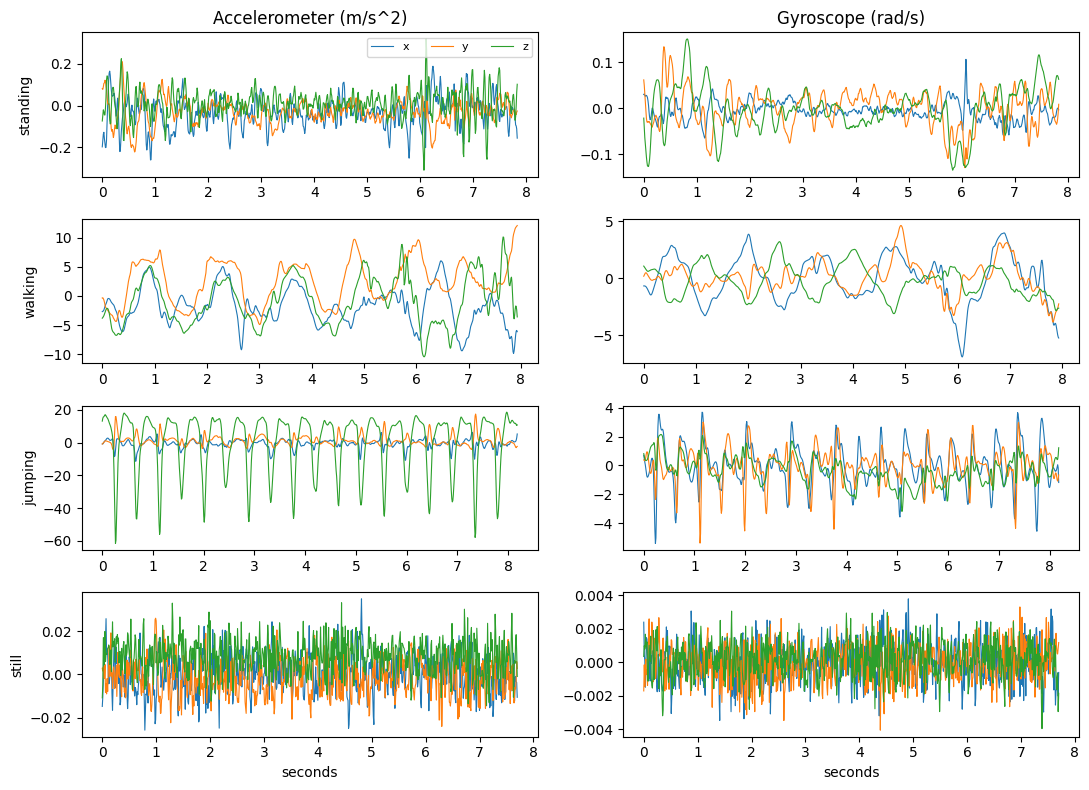

In [4]:
first_file = {}
for r in recordings:
    if r["split"] == "train" and r["activity"] not in first_file:
        first_file[r["activity"]] = r

fig, axes = plt.subplots(len(ACTIVITIES), 2, figsize=(11, 8), sharex=False)
for i, act in enumerate(ACTIVITIES):
    df = first_file[act]["df"]
    t = df.seconds - df.seconds.iloc[0]
    for ax_name, c in zip("xyz", ["tab:blue", "tab:orange", "tab:green"]):
        axes[i, 0].plot(t, df["acc_" + ax_name], color=c, lw=0.8, label=ax_name)
        axes[i, 1].plot(t, df["gyro_" + ax_name], color=c, lw=0.8, label=ax_name)
    axes[i, 0].set_ylabel(act)
    if i == 0:
        axes[i, 0].set_title("Accelerometer (m/s^2)")
        axes[i, 1].set_title("Gyroscope (rad/s)")
        axes[i, 0].legend(loc="upper right", ncol=3, fontsize=8)
axes[-1, 0].set_xlabel("seconds")
axes[-1, 1].set_xlabel("seconds")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "raw_signals.png"), dpi=150)
plt.show()

## 5. Windowing and feature extraction

I cut each recording into windows of 2 seconds. At 100 Hz that is 200 samples. I picked 2 seconds for two reasons. First, a normal walking pace is around 2 steps per second, so a 2 second window holds several full steps and the FFT can see the rhythm. Second, the FFT frequency resolution is 1 divided by the window length, which gives 0.5 Hz steps here. A window much shorter than this would blur the difference between walking and jumping. The windows overlap by 50 percent, so each window moves forward by 1 second.

Features per window, computed for the accelerometer and the gyroscope separately (16 features in total):

* `mean_mag`: mean of the signal magnitude. Shows the overall size of the motion.
* `std_mag`: standard deviation of the magnitude. Separates still and standing (tiny) from walking and jumping (large).
* `rms_mag`: root mean square of the magnitude. Reflects the energy of the motion.
* `sma`: signal magnitude area, the mean of |x|+|y|+|z|. Captures total movement over all axes.
* `corr_abs`: mean absolute correlation between the x, y and z axes. Jumping moves mostly along one direction, so the axes are strongly linked. Random sensor noise has weak links.
* `dom_freq`: dominant frequency from the FFT, between 0.5 and 20 Hz. Walking and jumping have different repeat rates.
* `spec_energy`: spectral energy from the FFT. Another measure of how strong the movement is, but based on the frequency content.
* `spec_entropy`: spectral entropy. A clean repeated movement puts its power in a few frequencies (low entropy). Noise spreads it everywhere (high entropy). This helps to tell still and standing from walking.

In [5]:
def sensor_features(xyz, fs):
    """Time and frequency features for one sensor in one window. xyz has shape (n, 3)."""
    n = len(xyz)
    mag = np.sqrt((xyz ** 2).sum(axis=1))
    f = {}
    f["mean_mag"] = mag.mean()
    f["std_mag"] = mag.std()
    f["rms_mag"] = np.sqrt((mag ** 2).mean())
    f["sma"] = np.abs(xyz).sum(axis=1).mean()
    with np.errstate(invalid="ignore", divide="ignore"):
        c = np.corrcoef(xyz.T)
    f["corr_abs"] = np.nan_to_num(np.mean(np.abs([c[0, 1], c[0, 2], c[1, 2]])))
    sig = (mag - mag.mean()) * np.hanning(n)
    power = np.abs(np.fft.rfft(sig)) ** 2
    freqs = np.fft.rfftfreq(n, 1.0 / fs)
    band = (freqs >= 0.5) & (freqs <= 20)
    p_band = power[band]
    f["dom_freq"] = freqs[band][np.argmax(p_band)]
    f["spec_energy"] = p_band.sum() / n
    p = p_band / (p_band.sum() + 1e-12)
    f["spec_entropy"] = -(p * np.log(p + 1e-12)).sum() / np.log(len(p))
    return f


SENSOR_COLS = {"acc": ["acc_x", "acc_y", "acc_z"], "gyro": ["gyro_x", "gyro_y", "gyro_z"]}


def extract_features(df, fs, win_sec, overlap):
    """Slide a window over one recording and return one row of features per window."""
    win = int(round(win_sec * fs))
    step = int(round(win * (1 - overlap)))
    rows = []
    for s in range(0, len(df) - win + 1, step):
        seg = df.iloc[s:s + win]
        feats = {}
        for sname, cols in SENSOR_COLS.items():
            for k, v in sensor_features(seg[cols].values, fs).items():
                feats[f"{sname}_{k}"] = v
        feats["t_start"] = seg.seconds.iloc[0]
        feats["t_end"] = seg.seconds.iloc[-1]
        labs = seg.activity.unique()
        feats["label"] = labs[0] if len(labs) == 1 and labs[0] != "transition" else "mixed"
        rows.append(feats)
    return pd.DataFrame(rows)


parts = []
for r in recordings:
    f = extract_features(r["df"], FS, WINDOW_SEC, OVERLAP)
    f["file"] = r["name"]
    f["split"] = r["split"]
    parts.append(f)
feat = pd.concat(parts, ignore_index=True)

META_COLS = ["t_start", "t_end", "label", "file", "split"]
FEATURE_COLS = [c for c in feat.columns if c not in META_COLS]
print("windows per split and label")
print(feat.groupby(["split", "label"]).size().unstack(fill_value=0))
print("number of features:", len(FEATURE_COLS))

windows per split and label
label  jumping  mixed  standing  still  walking
split                                          
test        19     19        16     13       15
train       85      0        79     82       87
number of features: 16


### Normalization

Some features, like the standard deviation, are about 0.01 when the phone is still and about 8 when I am jumping. A Gaussian model cannot describe a gap of that size well. So for the features that measure the size of the motion (`mean_mag`, `std_mag`, `rms_mag`, `sma`, `spec_energy`) I take the log first. Then I apply z-score normalization to every feature, which puts them all on the same scale with mean 0 and standard deviation 1. I chose z-score because the Gaussian emissions work best when features have similar scales, and it does not squash the data into a fixed range like min-max scaling would. The mean and standard deviation come from the training windows only, and the same numbers are then applied to the test windows, so the test data stays unseen.

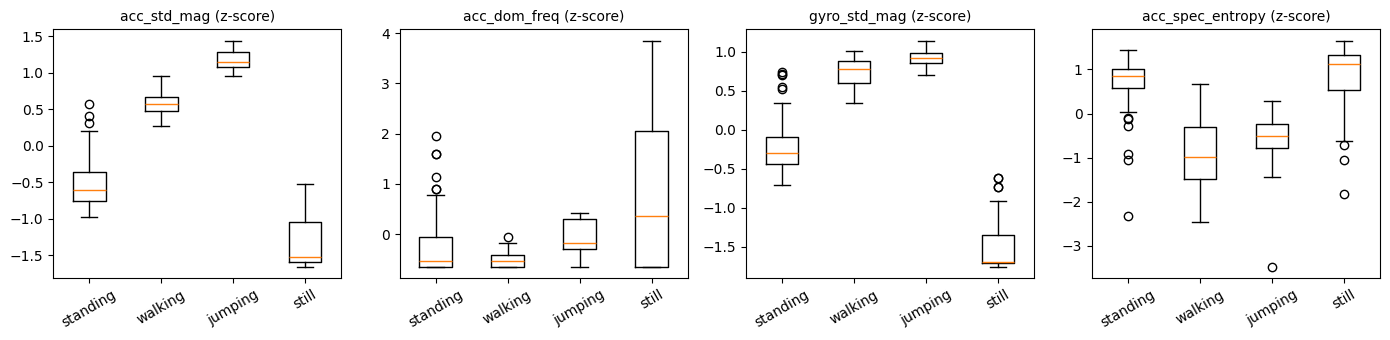

In [6]:
LOG_COLS = [c for c in FEATURE_COLS if any(k in c for k in ["mean_mag", "std_mag", "rms_mag", "sma", "spec_energy"])]

feat_log = feat.copy()
feat_log[LOG_COLS] = np.log(feat[LOG_COLS] + 1e-8)

train_mask = feat.split == "train"
feat_mean = feat_log.loc[train_mask, FEATURE_COLS].mean()
feat_std = feat_log.loc[train_mask, FEATURE_COLS].std().replace(0, 1.0)

feat_z = feat_log.copy()
feat_z[FEATURE_COLS] = (feat_log[FEATURE_COLS] - feat_mean) / feat_std
feat_z.to_csv(os.path.join(RES_DIR, "features_normalized.csv"), index=False)

show = ["acc_std_mag", "acc_dom_freq", "gyro_std_mag", "acc_spec_entropy"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
tr = feat_z[feat_z.split == "train"]
for ax, col in zip(axes, show):
    ax.boxplot([tr.loc[tr.label == a, col] for a in ACTIVITIES])
    ax.set_xticks(range(1, len(ACTIVITIES) + 1))
    ax.set_xticklabels(ACTIVITIES, rotation=30)
    ax.set_title(col + " (z-score)", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "feature_boxplots.png"), dpi=150)
plt.show()

## 6. The HMM, written from scratch with numpy

Model parts:

* Hidden states Z: standing, walking, jumping, still (4 states)
* Observations X: the 16 normalized features of each window
* Initial probabilities (pi): how likely a sequence starts in each state
* Transition matrix (A): the chance of going from one activity to another from one window to the next
* Emission probabilities (B): a Gaussian for each state with a diagonal covariance, so each feature has its own mean and variance in each state

All the forward and backward calculations are done in log space so that long sequences do not underflow to zero.

Baum-Welch trains the model. It repeats an expectation step (forward and backward passes to get the probability of each state at each window) and a maximization step (update pi, A and the Gaussian means and variances). It stops when the average log-likelihood per window improves by less than a small tolerance, with a maximum number of iterations as a backup. Viterbi then finds the single most likely path of states for a new sequence.

In [7]:
def logsumexp(a, axis):
    """Stable log of the sum of exponentials along one axis."""
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    s = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return np.squeeze(s, axis=axis)


class GaussianHMM:
    """Hidden Markov Model with diagonal Gaussian emissions."""

    def __init__(self, pi, A, means, variances, var_floor=0.02):
        self.pi = np.array(pi, dtype=float)
        self.A = np.array(A, dtype=float)
        self.means = np.array(means, dtype=float)
        self.vars = np.maximum(np.array(variances, dtype=float), var_floor)
        self.var_floor = var_floor
        self.K = len(self.pi)

    def log_emission(self, X):
        """Log probability of every window under every state. Shape (T, K)."""
        T, D = X.shape
        out = np.zeros((T, self.K))
        for k in range(self.K):
            diff = X - self.means[k]
            out[:, k] = -0.5 * np.sum(np.log(2 * np.pi * self.vars[k]) + diff ** 2 / self.vars[k], axis=1)
        return out

    def forward(self, logB):
        """Forward pass in log space. Returns log alpha and the sequence log-likelihood."""
        T = logB.shape[0]
        logA = np.log(self.A + 1e-300)
        la = np.zeros((T, self.K))
        la[0] = np.log(self.pi + 1e-300) + logB[0]
        for t in range(1, T):
            la[t] = logB[t] + logsumexp(la[t - 1][:, None] + logA, axis=0)
        return la, logsumexp(la[-1], axis=0)

    def backward(self, logB):
        """Backward pass in log space."""
        T = logB.shape[0]
        logA = np.log(self.A + 1e-300)
        lb = np.zeros((T, self.K))
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + logB[t + 1] + lb[t + 1], axis=1)
        return lb

    def viterbi(self, X):
        """Most likely state path for one sequence of feature vectors."""
        logB = self.log_emission(X)
        logA = np.log(self.A + 1e-300)
        T = X.shape[0]
        delta = np.zeros((T, self.K))
        psi = np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi + 1e-300) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA
            psi[t] = np.argmax(scores, axis=0)
            delta[t] = logB[t] + np.max(scores, axis=0)
        path = np.zeros(T, dtype=int)
        path[-1] = np.argmax(delta[-1])
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path

    def fit(self, sequences, max_iter=200, tol=1e-4, verbose=True):
        """Baum-Welch on a list of sequences. Stops when the per-window log-likelihood gain is below tol."""
        n_windows = sum(len(s) for s in sequences)
        D = sequences[0].shape[1]
        history = []
        converged = False
        for it in range(1, max_iter + 1):
            pi_acc = np.zeros(self.K)
            xi_acc = np.zeros((self.K, self.K))
            g_sum = np.zeros(self.K)
            gx_sum = np.zeros((self.K, D))
            gx2_sum = np.zeros((self.K, D))
            total_ll = 0.0
            logA = np.log(self.A + 1e-300)
            for X in sequences:
                logB = self.log_emission(X)
                la, ll = self.forward(logB)
                lb = self.backward(logB)
                total_ll += ll
                gamma = np.exp(la + lb - ll)
                pi_acc += gamma[0]
                g_sum += gamma.sum(axis=0)
                gx_sum += gamma.T @ X
                gx2_sum += gamma.T @ (X ** 2)
                if len(X) > 1:
                    logxi = la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll
                    xi_acc += np.exp(logxi).sum(axis=0)
            history.append(total_ll / n_windows)
            if it > 1 and abs(history[-1] - history[-2]) < tol:
                converged = True
                if verbose:
                    print(f"iteration {it:3d}  log-likelihood per window {history[-1]:.4f}")
                break
            self.pi = (pi_acc + 1e-3) / (pi_acc + 1e-3).sum()
            xi_acc = xi_acc + 1e-3
            self.A = xi_acc / xi_acc.sum(axis=1, keepdims=True)
            self.means = gx_sum / g_sum[:, None]
            self.vars = np.maximum(gx2_sum / g_sum[:, None] - self.means ** 2, self.var_floor)
            if verbose and (it == 1 or it % 10 == 0):
                print(f"iteration {it:3d}  log-likelihood per window {history[-1]:.4f}")
        if verbose:
            print(f"stopped at iteration {it}, converged = {converged}")
        return history, converged

## 7. Training sequences and the starting values

A Baum-Welch model needs sequences, and my training files each hold only one activity. If I used them one by one, the transition matrix would show almost no switching between activities. So I build longer training sequences by joining 4 to 6 recordings of different activities in a random order, and I make the next activity different from the one before. This means the transition probabilities come from how I joined the files, not from a real day of behavior. I keep this in mind when I discuss the transition matrix.

For the starting values I use the labeled windows: the mean and variance of each state come from the windows of that activity, and the transition counts and starting counts come from the joined sequences. This keeps state 0 as standing, state 1 as walking, state 2 as jumping and state 3 as still while Baum-Welch improves the numbers.

In [8]:
train_df = feat_z[feat_z.split == "train"]
by_file = {a: [] for a in ACTIVITIES}
for fname, g in train_df.groupby("file"):
    g = g.sort_values("t_start")
    act = g.label.iloc[0]
    by_file[act].append(g[FEATURE_COLS].values)

N_SEQUENCES = 60


def build_sequences(by_file, n_seq, rng):
    """Join recordings of different activities into longer sequences with their state labels."""
    seqs, labels = [], []
    for _ in range(n_seq):
        n_seg = int(rng.integers(4, 7))
        prev = None
        xs, ys = [], []
        for _ in range(n_seg):
            choices = [i for i in range(len(ACTIVITIES)) if i != prev]
            a = int(rng.choice(choices))
            X = by_file[ACTIVITIES[a]][int(rng.integers(len(by_file[ACTIVITIES[a]])))]
            xs.append(X)
            ys.append(np.full(len(X), a))
            prev = a
        seqs.append(np.vstack(xs))
        labels.append(np.concatenate(ys))
    return seqs, labels


train_seqs, train_labels = build_sequences(by_file, N_SEQUENCES, rng)
K, D = len(ACTIVITIES), len(FEATURE_COLS)

# starting values from the labeled windows
init_means = np.zeros((K, D))
init_vars = np.zeros((K, D))
for k, a in enumerate(ACTIVITIES):
    Xa = np.vstack(by_file[a])
    init_means[k] = Xa.mean(axis=0)
    init_vars[k] = Xa.var(axis=0)

counts = np.ones((K, K))
start_counts = np.ones(K)
for y in train_labels:
    start_counts[y[0]] += 1
    for i, j in zip(y[:-1], y[1:]):
        counts[i, j] += 1
init_A = counts / counts.sum(axis=1, keepdims=True)
init_pi = start_counts / start_counts.sum()

model = GaussianHMM(init_pi, init_A, init_means, init_vars)
print("training sequences:", len(train_seqs), "| windows:", sum(len(s) for s in train_seqs))
history, converged = model.fit(train_seqs, max_iter=200, tol=1e-4)

training sequences: 60 | windows: 1970
iteration   1  log-likelihood per window -2.9491
iteration  10  log-likelihood per window -2.2593
iteration  11  log-likelihood per window -2.2593
stopped at iteration 11, converged = True


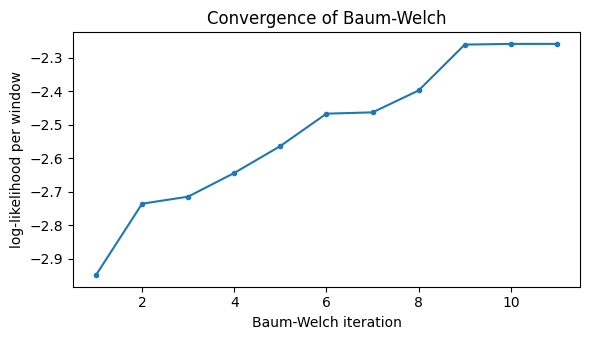

training accuracy of Viterbi on the joined sequences: 0.9269


In [9]:
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(history) + 1), history, marker="o", ms=3)
plt.xlabel("Baum-Welch iteration")
plt.ylabel("log-likelihood per window")
plt.title("Convergence of Baum-Welch")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "baum_welch_convergence.png"), dpi=150)
plt.show()

# check that each state still matches its activity on the training sequences
pred_train = np.concatenate([model.viterbi(s) for s in train_seqs])
true_train = np.concatenate(train_labels)
print("training accuracy of Viterbi on the joined sequences:", round((pred_train == true_train).mean(), 4))

## 8. Transition matrix and emission probabilities

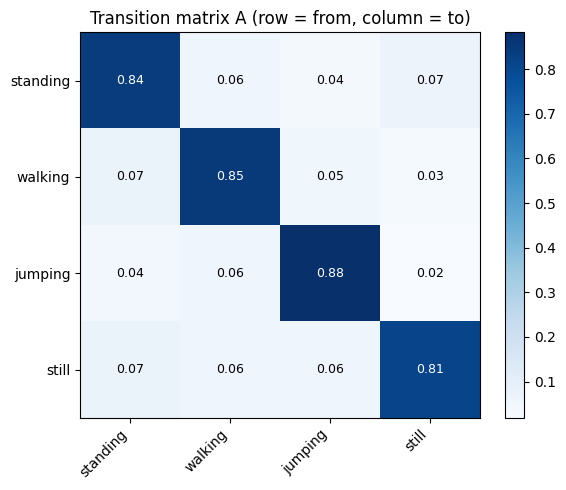

pi: {'standing': 0.3, 'walking': 0.217, 'jumping': 0.233, 'still': 0.25}


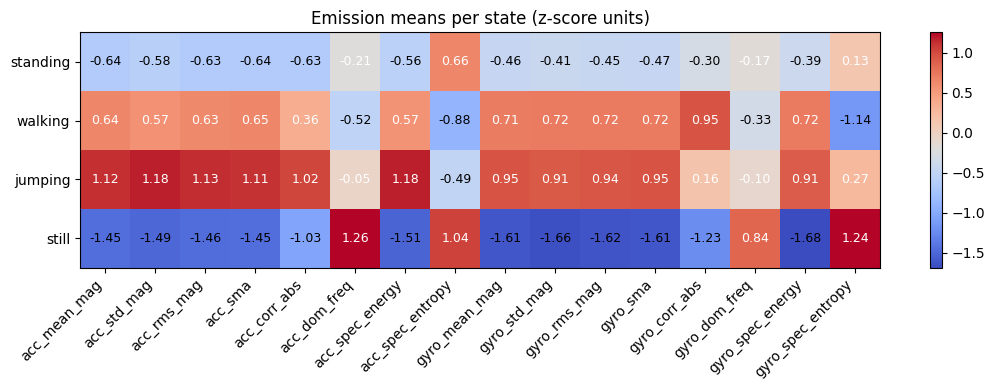

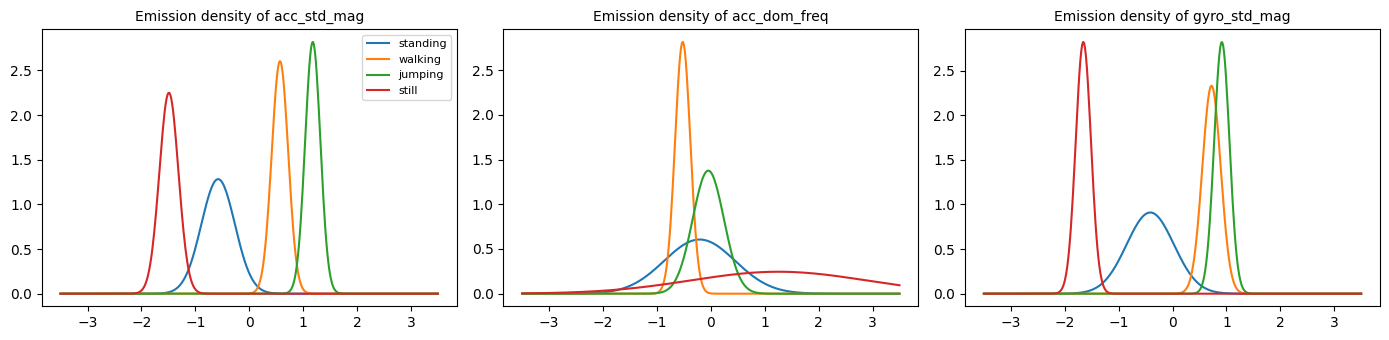

In [10]:
def heatmap(M, xlabels, ylabels, title, path, fmt="{:.2f}", cmap="Blues", figsize=(6, 5)):
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(M, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(xlabels)))
    ax.set_xticklabels(xlabels, rotation=45, ha="right")
    ax.set_yticks(range(len(ylabels)))
    ax.set_yticklabels(ylabels)
    thr = (np.nanmax(M) + np.nanmin(M)) / 2
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center",
                    color="white" if M[i, j] > thr else "black", fontsize=9)
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


heatmap(model.A, ACTIVITIES, ACTIVITIES, "Transition matrix A (row = from, column = to)",
        os.path.join(FIG_DIR, "transition_matrix.png"))
print("pi:", {a: round(float(p), 3) for a, p in zip(ACTIVITIES, model.pi)})
pd.DataFrame(model.A, index=ACTIVITIES, columns=ACTIVITIES).to_csv(os.path.join(RES_DIR, "transition_matrix.csv"))

heatmap(model.means, FEATURE_COLS, ACTIVITIES, "Emission means per state (z-score units)",
        os.path.join(FIG_DIR, "emission_means.png"), cmap="coolwarm", figsize=(11, 4))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["acc_std_mag", "acc_dom_freq", "gyro_std_mag"]):
    j = FEATURE_COLS.index(col)
    xs = np.linspace(-3.5, 3.5, 400)
    for k, a in enumerate(ACTIVITIES):
        sd = np.sqrt(model.vars[k, j])
        ax.plot(xs, np.exp(-0.5 * ((xs - model.means[k, j]) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)), label=a)
    ax.set_title("Emission density of " + col, fontsize=10)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "emission_densities.png"), dpi=150)
plt.show()

## 9. Evaluation on unseen data

The two test recordings were not used for training, and the normalization numbers came from the training windows only. For each test file I decode the whole sequence of windows with Viterbi. I only score windows that sit fully inside one labeled segment. Windows that touch a gap where I was changing activity are decoded but not scored, because their true label is not clear.

For each activity I count one against the rest:

* Sensitivity = TP / (TP + FN)
* Specificity = TN / (TN + FP)
* Accuracy for that activity = (TP + TN) / all scored windows

In [11]:
def confusion(true_idx, pred_idx, K):
    cm = np.zeros((K, K), dtype=int)
    for t, p in zip(true_idx, pred_idx):
        cm[t, p] += 1
    return cm


def metrics_table(cm):
    """Per activity sensitivity, specificity and accuracy from a confusion matrix (rows = true)."""
    total = cm.sum()
    rows = []
    for k, a in enumerate(ACTIVITIES):
        tp = cm[k, k]
        fn = cm[k].sum() - tp
        fp = cm[:, k].sum() - tp
        tn = total - tp - fn - fp
        rows.append({
            "State (Activity)": a,
            "Number of Samples": int(cm[k].sum()),
            "Sensitivity": round(tp / (tp + fn), 4) if tp + fn else np.nan,
            "Specificity": round(tn / (tn + fp), 4) if tn + fp else np.nan,
            "Accuracy (one vs rest)": round((tp + tn) / total, 4),
        })
    return pd.DataFrame(rows)


test_df = feat_z[feat_z.split == "test"]
decoded = {}
all_true, all_pred = [], []
per_file_cm = {}
for fname, g in test_df.groupby("file"):
    g = g.sort_values("t_start").reset_index(drop=True)
    path = model.viterbi(g[FEATURE_COLS].values)
    scored = g.label.isin(ACTIVITIES).values
    true_idx = g.label[scored].map({a: i for i, a in enumerate(ACTIVITIES)}).values
    pred_idx = path[scored]
    per_file_cm[fname] = confusion(true_idx, pred_idx, K)
    all_true.extend(true_idx)
    all_pred.extend(pred_idx)
    decoded[fname] = (g, path)
    print(fname, "windows decoded:", len(g), "| windows scored:", int(scored.sum()),
          "| accuracy:", round((true_idx == pred_idx).mean(), 4))

cm_all = confusion(all_true, all_pred, K)
table = metrics_table(cm_all)
overall = np.trace(cm_all) / cm_all.sum()
print()
print(table.to_string(index=False))
print()
print("Overall accuracy over both test files:", round(overall, 4))
table.to_csv(os.path.join(RES_DIR, "test_metrics_table.csv"), index=False)
pd.DataFrame(cm_all, index=ACTIVITIES, columns=ACTIVITIES).to_csv(os.path.join(RES_DIR, "test_confusion_matrix.csv"))

test-01 windows decoded: 42 | windows scored: 33 | accuracy: 0.9697
test-02 windows decoded: 40 | windows scored: 30 | accuracy: 0.9667

State (Activity)  Number of Samples  Sensitivity  Specificity  Accuracy (one vs rest)
        standing                 16       1.0000       0.9574                  0.9683
         walking                 15       1.0000       1.0000                  1.0000
         jumping                 19       1.0000       1.0000                  1.0000
           still                 13       0.8462       1.0000                  0.9683

Overall accuracy over both test files: 0.9683


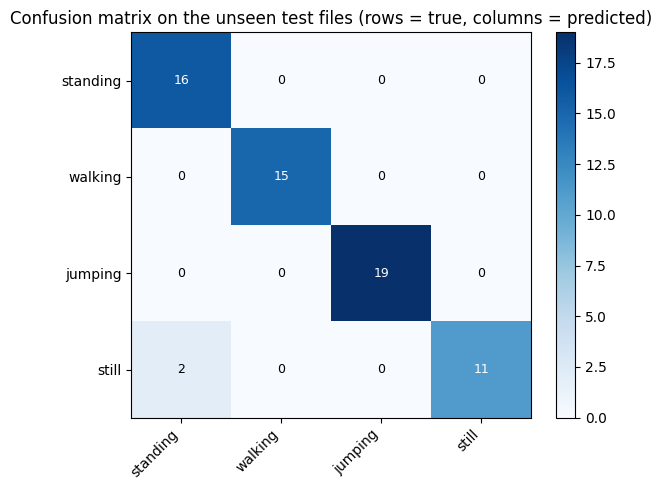

test-01 confusion matrix (rows = true, columns = predicted)
          standing  walking  jumping  still
standing         8        0        0      0
walking          0        8        0      0
jumping          0        0       10      0
still            1        0        0      6

test-02 confusion matrix (rows = true, columns = predicted)
          standing  walking  jumping  still
standing         8        0        0      0
walking          0        7        0      0
jumping          0        0        9      0
still            1        0        0      5



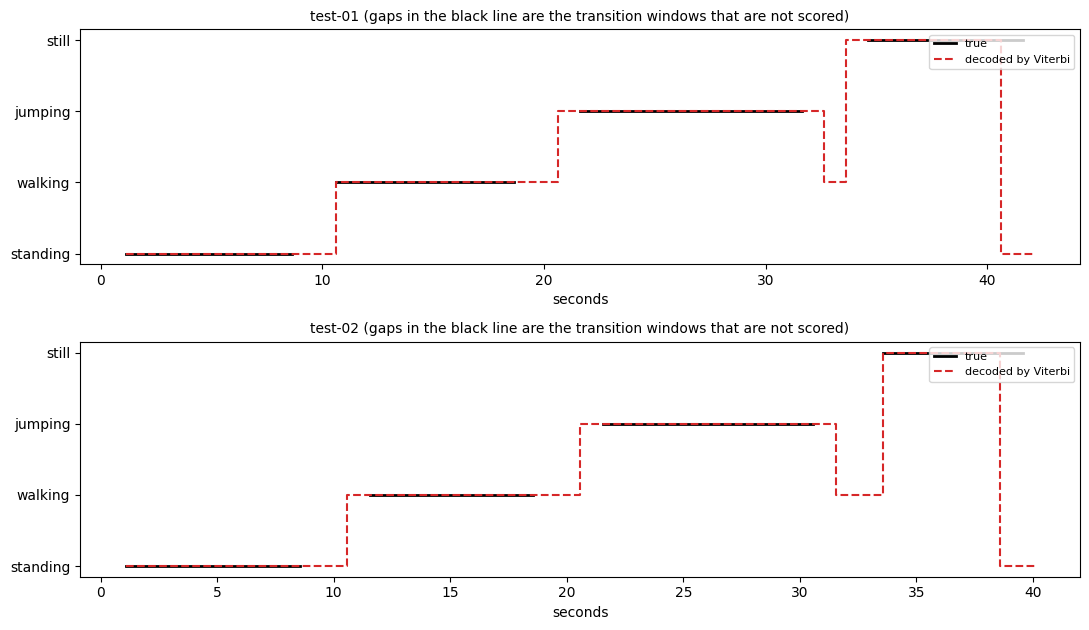

In [12]:
heatmap(cm_all.astype(float), ACTIVITIES, ACTIVITIES,
        "Confusion matrix on the unseen test files (rows = true, columns = predicted)",
        os.path.join(FIG_DIR, "confusion_matrix_test.png"), fmt="{:.0f}", figsize=(6, 5))

for fname, cm in per_file_cm.items():
    print(fname, "confusion matrix (rows = true, columns = predicted)")
    print(pd.DataFrame(cm, index=ACTIVITIES, columns=ACTIVITIES))
    print()

fig, axes = plt.subplots(len(decoded), 1, figsize=(11, 3.2 * len(decoded)), sharey=True)
axes = np.atleast_1d(axes)
for ax, (fname, (g, path)) in zip(axes, decoded.items()):
    t = (g.t_start + g.t_end) / 2
    true_plot = g.label.map({a: i for i, a in enumerate(ACTIVITIES)}).astype(float)
    ax.step(t, true_plot, where="mid", color="black", lw=2, label="true")
    ax.step(t, path + 0.0, where="mid", color="tab:red", lw=1.5, ls="--", label="decoded by Viterbi")
    ax.set_yticks(range(K))
    ax.set_yticklabels(ACTIVITIES)
    ax.set_title(fname + " (gaps in the black line are the transition windows that are not scored)", fontsize=10)
    ax.set_xlabel("seconds")
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "decoded_sequences_test.png"), dpi=150)
plt.show()

## 10. Save the final numbers

The cell below saves the model parameters so I can quote the exact numbers in the report.

In [13]:
params = {
    "sampling_rate_hz": FS,
    "window_seconds": WINDOW_SEC,
    "overlap": OVERLAP,
    "n_features": len(FEATURE_COLS),
    "features": FEATURE_COLS,
    "baum_welch_iterations": len(history),
    "baum_welch_converged": bool(converged),
    "final_loglik_per_window": float(history[-1]),
    "pi": dict(zip(ACTIVITIES, model.pi.round(4).tolist())),
    "overall_test_accuracy": float(round(overall, 4)),
}
with open(os.path.join(RES_DIR, "model_summary.json"), "w") as fh:
    json.dump(params, fh, indent=2)
print(json.dumps({k: v for k, v in params.items() if k != "features"}, indent=2))

{
  "sampling_rate_hz": 100,
  "window_seconds": 2.0,
  "overlap": 0.5,
  "n_features": 16,
  "baum_welch_iterations": 11,
  "baum_welch_converged": true,
  "final_loglik_per_window": -2.259281354468523,
  "pi": {
    "standing": 0.3,
    "walking": 0.2166,
    "jumping": 0.2333,
    "still": 0.25
  },
  "overall_test_accuracy": 0.9683
}
